# Scientific Data Analyzer

## Project Objective

Analyze simulated experimental measurementsusing Python.

## Dataset

The dataset contains 30 measurements generated from a linear model with Gaussian random noise.

## Methods

- Descriptive statistics
- Data visualization
- Linear regression
- Residual analysis

## Tools

Python, NumPy, Pandas, Matplotlib, SciPy

In [1]:
import numpy as np
import pandas as pd

#Create a random number generator
rng = np.random.default_rng(42)

#Generate 30 measurement days
days = np.arange(1,31)

#Generate experiemtnal measurements
measurements = 20 +0.5 * days + rng.normal(0,2,30)

#Organize measurements into a table
df = pd.DataFrame({
    "Day":days,
    "Measurement": measurements
})

#Save measurements to a CSV file
df.to_csv("data/experimental_data.csv", index=False)

#Display the first five measurements
df.head()

,Day,Measurement
0,1,21.109434
1,2,18.920032
2,3,23.000902
3,4,23.881129
4,5,18.597930


In [2]:
#Read the CSV file back into Python
data = pd.read_csv("data/experimental_data.csv")

#Inspect the dataset
print(data.head())

#Check the number of rows and columns
print("Dataset shape:", data.shape)

   Day  Measurement
0    1    21.109434
1    2    18.920032
2    3    23.000902
3    4    23.881129
4    5    18.597930
Dataset shape: (30, 2)


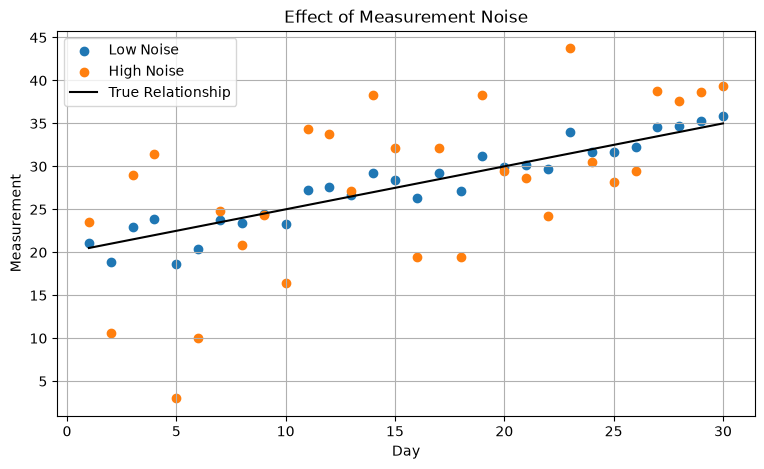

In [3]:
import matplotlib.pyplot as plt

days = np.arange(1, 31)

rng = np.random.default_rng(42)

#Generate the same random noise pattern
noise = rng.normal(0,1,30)

#Two datasets with different noise levels
low_noise = 20 + 0.5 * days + 2*noise
high_noise = 20 + 0.5 * days + 10*noise

#True underlying relationship
true_line = 20 + 0.5 * days

plt.figure(figsize=(9,5))

plt.scatter(days, low_noise, label="Low Noise")
plt.scatter(days, high_noise, label="High Noise")

plt.plot(days, true_line, color="black",
         label="True Relationship")

plt.xlabel("Day")
plt.ylabel("Measurement")
plt.title("Effect of Measurement Noise")
plt.legend()
plt.grid(True)

plt.show()

In [4]:
#Load experimental measurements
df = pd.read_csv("data/experimental_data.csv")

#Display the first five rows
print(df.head())

   Day  Measurement
0    1    21.109434
1    2    18.920032
2    3    23.000902
3    4    23.881129
4    5    18.597930


In [5]:
#Check dimensions
print("Shape:", df.shape)

#Check column names
print("Columns:", df.columns.tolist())

#Check data types and completeness
df.info()

Shape: (30, 2)
Columns: ['Day', 'Measurement']
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Day          30 non-null     int64  
 1   Measurement  30 non-null     float64
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes


In [6]:
#Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
Day            0
Measurement    0
dtype: int64


In [7]:
#Calculate summary statistics
print(df.describe())

             Day  Measurement
count  30.000000    30.000000
mean   15.500000    27.783628
std     8.803408     4.935862
min     1.000000    18.597930
25%     8.250000    23.787043
50%    15.500000    27.995301
75%    22.750000    31.546733
max    30.000000    35.861642


In [8]:
mean_value = df["Measurement"].mean()
std_value = df["Measurement"].std()

print("Mean:", mean_value)
print("Standard deviation:", std_value)

Mean: 27.783628241615435
Standard deviation: 4.935862489039588


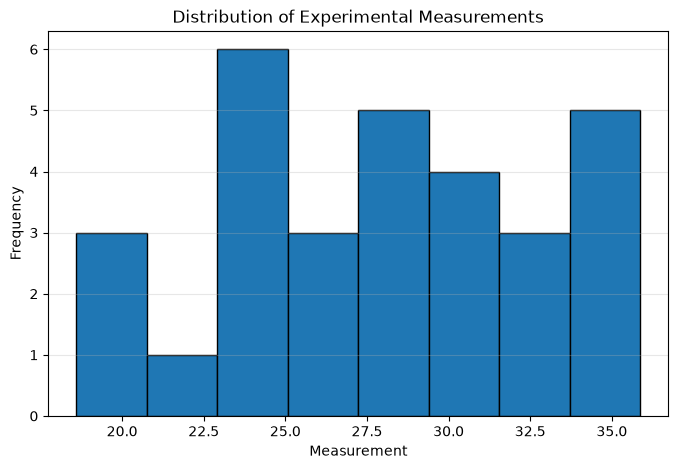

In [9]:
plt.figure(figsize=(8,5))

plt.hist(df["Measurement"], bins=8, edgecolor="black")

plt.xlabel("Measurement")
plt.ylabel("Frequency")
plt.title("Distribution of Experimental Measurements")
plt.grid(axis="y", alpha=0.3)

plt.show()

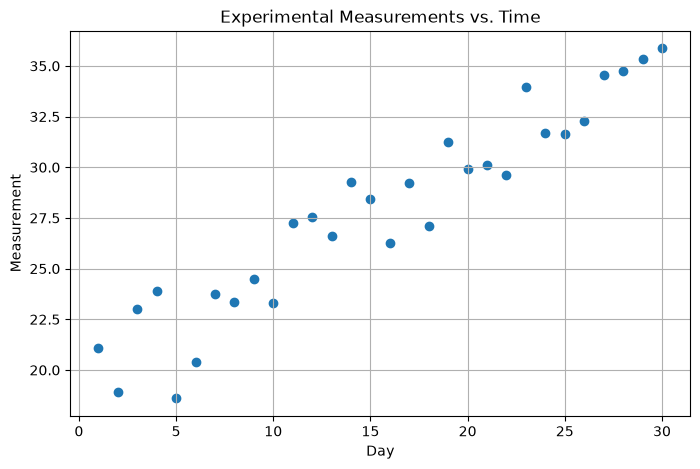

In [10]:
plt.figure(figsize=(8,5))

plt.scatter(df["Day"], df["Measurement"])

plt.xlabel("Day")
plt.ylabel("Measurement")
plt.title("Experimental Measurements vs. Time")
plt.grid(True)

plt.savefig("results/experimental_scatter.png",
            dpi=300, bbox_inches="tight")
plt.show()

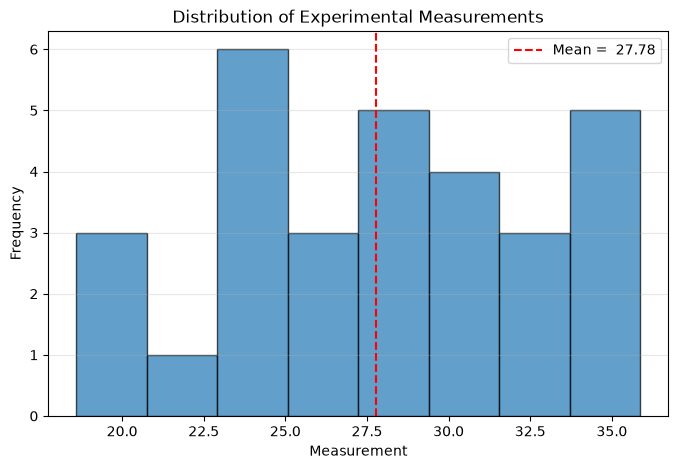

In [12]:
#Calculate mea
mean_value = df["Measurement"].mean()

#Create histogram
plt.figure(figsize=(8,5))

plt.hist(
    df["Measurement"],
    bins=8,
    edgecolor="black",
    alpha=0.7
)

#Add vertical line at mean
plt.axvline(
    mean_value,
    color="red",
    linestyle="--",
    label=f"Mean = {mean_value: .2f}"
)
plt.xlabel("Measurement")
plt.ylabel("Frequency")
plt.title("Distribution of Experimental Measurements")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "results/measurement_historgram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# Extract data from the Dataframe
x=df["Day"].to_numpy()
y=df["Measurement"].to_numpy()

# Calculate the means
x_mean = np.mean(x)
y_mean = np.mean(y)

# Calculate the slope
numerator = np.sum((x - x_mean) * (y - y_mean))
denominator = np.sum((x - x_mean)**2)

slope = numerator / denominator

#Calculate the intercept
intercept = y_mean - slope * x_mean

print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")

Slope: 0.5332
Intercept: 19.5188


In [16]:
from scipy.stats import linregress
result = linregress(x, y)

print("Manual slope:", slope)
print("SciPy slope:", result.slope)

print("Manual Intercept:", intercept)
print("SciPy Intercept:", result.intercept)

print("Slopes match:",
      np.isclose(slope, result.slope))

print("Intercepts match:",
      np.isclose(intercept, result.intercept))

Manual slope: 0.5332178327853161
SciPy slope: 0.5332178327853161
Manual Intercept: 19.518751833443034
SciPy Intercept: 19.518751833443034
Slopes match: True
Intercepts match: True


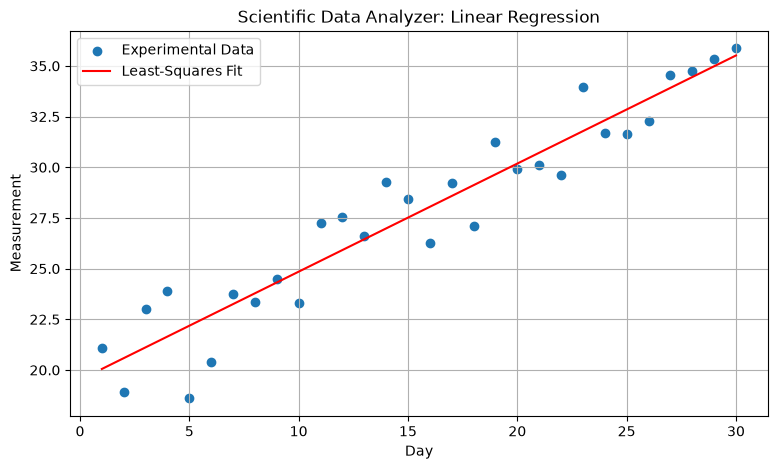

In [17]:
# Calculate predicted measurements
y_pred = slope * x + intercept

plt.figure(figsize=(9,5))

# Plot experimental line
plt.scatter(x, y, label="Experimental Data")

# Plot regression line
plt.plot(x, y_pred, color="red",
            label="Least-Squares Fit")

plt.xlabel("Day")
plt.ylabel("Measurement")
plt.title("Scientific Data Analyzer: Linear Regression")
plt.legend()
plt.grid(True)

# Save the figure
plt.savefig(
    "results/linear_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
residuals = y - y_pred
sse = np.sum(residuals ** 2)
print(f"SSE: {sse:.4f}")

SSE: 67.5074


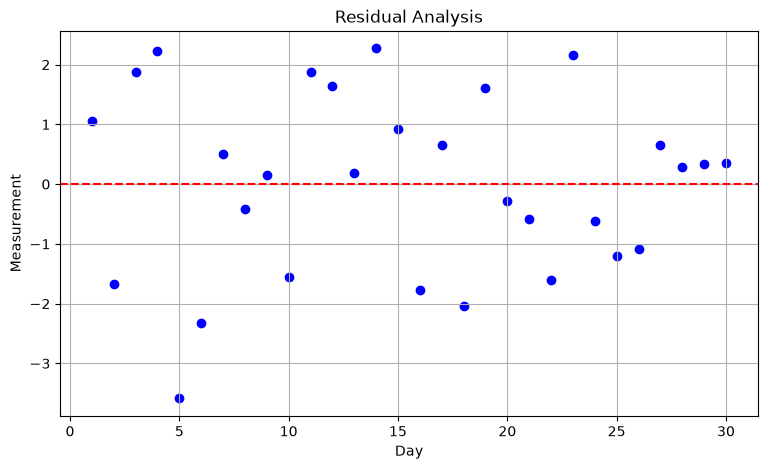

In [19]:
plt.figure(figsize=(9, 5))

plt.scatter(x, residuals, color="blue")

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Day")
plt.ylabel("Measurement")
plt.title("Residual Analysis")
plt.grid(True)

plt.savefig(
    "results/residual_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# Number of observations
n = len(y)

#Calculate mean sqaured error
mse = sse / n

#Calculate root mean squared error
rmse = np.sqrt(mse)

print(f"Number of observations: {n}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")

Number of observations: 30
MSE: 2.2502
RMSE: 1.5001


In [22]:
# Calculate total sum of sqaures
sst = np.sum((y - np.mean(y)) ** 2)

# Calculate R-squared
r_squared = 1 - (sse / sst)

print(f"SST: {sst:.4f}")
print(f"R-squared: {r_squared:.4f}")

SST: 706.5194
R-squared: 0.9045


In [23]:
residual_std_error = np.sqrt(sse / (n - 2))
print(f"Residual standard error: {residual_std_error:.4f}")

Residual standard error: 1.5527


In [24]:
mae = np.mean(np.abs(residuals))
print(f"MAE: {mae:.4f}")

MAE: 1.2500


## Modular Programming and Reusable Functions

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

In [26]:
def load_data(filepath):
    data = pd.read_csv(filepath)
    return data

In [27]:
df = load_data("data/experimental_data.csv")

print(df.head())

   Day  Measurement
0    1    21.109434
1    2    18.920032
2    3    23.000902
3    4    23.881129
4    5    18.597930


In [30]:
def calculate_statistics(data):
    measurements = data["Measurement"]

    statistics = {
    "mean": measurements.mean(),
    "std": measurements.std(),
    "min": measurements.min(),
    "max": measurements.max(),
    "count": measurements.count()
    }
    return statistics

In [31]:
stats = calculate_statistics(df)

print(stats)

{'mean': np.float64(27.783628241615435), 'std': np.float64(4.935862489039588), 'min': np.float64(18.597929622692327), 'max': np.float64(35.861642006015764), 'count': np.int64(30)}


In [32]:
print(f"Mean: {stats['mean']:.4f}")
print(f"Std: {stats['std']:.4f}")

Mean: 27.7836
Std: 4.9359


In [33]:
def calculate_regression(x, y):
    result = linregress(x, y)

    slope = result.slope
    intercept = result.intercept

    y_pred = slope * x + intercept

    return slope, intercept, y_pred

In [34]:
x = df["Day"].to_numpy()
y = df["Measurement"].to_numpy()

slope, intercept, y_pred = calculate_regression(x, y)

print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")

Slope: 0.5332
Intercept: 19.5188


In [42]:
def evaluate_model(y, y_pred):
    residuals = y-y_pred

    sse = np.sum(residuals**2)
    sst = np.sum((y - np.mean(y))**2)

    mse = np.mean(residuals**2)
    rmse = np.sqrt(mse)

    r_sqaured = 1 - sse / sst

    metrics = {
    "SSE": sse,
    "MSE": mse,
    "RMSE": rmse,
    "MAE": mae,
    "R2": r_squared
    }
    return metrics

In [43]:
metrics = evaluate_model(y, y_pred)

print(metrics)

{'SSE': np.float64(67.50739125292898), 'MSE': np.float64(2.2502463750976327), 'RMSE': np.float64(1.5000821227844936), 'MAE': np.float64(1.2499821338841344), 'R2': np.float64(0.9044507629278188)}


In [44]:
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

SSE: 67.5074
MSE: 2.2502
RMSE: 1.5001
MAE: 1.2500
R2: 0.9045


In [45]:
def calculate_residuals(y, y_pred):
    residuals = y - y_pred

    return residuals

In [46]:
residuals = calculate_residuals(y, y_pred)

print(residuals)

[ 1.05746449 -1.66515571  1.88249706  2.22950627 -3.58691137 -2.32241784
  0.50440414 -0.41697968  0.14868536 -1.55701802  1.87464796  1.63821804
  0.18147774  2.27068092  0.91799936 -1.76882208  0.65404658 -2.03443803
  1.60700995 -0.28296031 -0.58605105 -1.61140324  2.16232069 -0.62503878
 -1.2058533  -1.08668259  0.64898505  0.28203698  0.34339624  0.34635519]


In [47]:
print(f"Residual sum: {np.sum(residuals):.10f}")
print(f"Residual mean: {np.mean(residuals):.1f}")

Residual sum: 0.0000000000
Residual mean: 0.0
